# Домашнее задание. Свёрточные сети



Здесь вам предстоит построить и обучить свою первую свёрточную сеть для классификации изображений на данных CIFAR10.

In [1]:
import tensorflow as tf

# Прогресс-бар для цикла обучения в Evaluator.
try:
    from tqdm.notebook import tqdm_notebook
except ImportError:
    from tqdm import tqdm as tqdm_notebook

In [ ]:
# Проверяем, есть ли GPU. Если есть — считаем на нём, иначе на CPU.
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print('Есть GPU:', gpus)
else:
    print('GPU нет, считаем на CPU')

GPU нет, считаем на CPU


## Данные



CIFAR10

* 60000 RGB изображений размером 32x32x3

* 10 классов: самолёты, собаки, рыбы и т.п.



<img src="https://www.samyzaf.com/ML/cifar10/cifar1.jpg" style="width:60%">

Загрузите данные, разделите их на обучающую и тестовую выборки. Размер тестовой выборки должен быть $10^4$.

In [3]:
# Чтобы keras не качал данные заново, кладём заранее скачанный архив в его кэш.
import shutil
from pathlib import Path

nb_file = globals().get('__vsc_ipynb_file__')
base_dir = Path(nb_file).parent if nb_file else Path.cwd()
local_archive = base_dir / 'cifar-10-python.tar.gz'

cache_dir = Path.home() / '.keras' / 'datasets'
cache_dir.mkdir(parents=True, exist_ok=True)

archive_target = cache_dir / 'cifar-10-batches-py-target_archive'
extract_dir = cache_dir / 'cifar-10-batches-py-target'

if extract_dir.is_file():
    extract_dir.unlink()

if local_archive.exists():
    shutil.copy(local_archive, archive_target)
    print('Локальный архив найден:', local_archive)
else:
    print('Локального архива нет, keras скачает данные сам')

Локальный архив найден: d:\NAS\wolftik\repository\github\netology_data_science\Темы\4. Основы нейронных сетей\03. Введение в сверточные НС\cifar-10-python.tar.gz


In [4]:
import numpy as np

from keras.datasets import cifar10

from sklearn.model_selection import train_test_split

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=10**4, random_state=42)



class_names = np.array(['airplane','automobile ','bird ','cat ','deer ','dog ','frog ','horse ','ship ','truck'])



print (X_train.shape,y_train.shape)

(40000, 32, 32, 3) (40000, 1)


c:\Users\wolftik\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = RestrictedUnpickler(f, encoding="bytes").load()


Прежде чем приступать к основной работе, стоит убедиться что загруженно именно то, что требовалось:

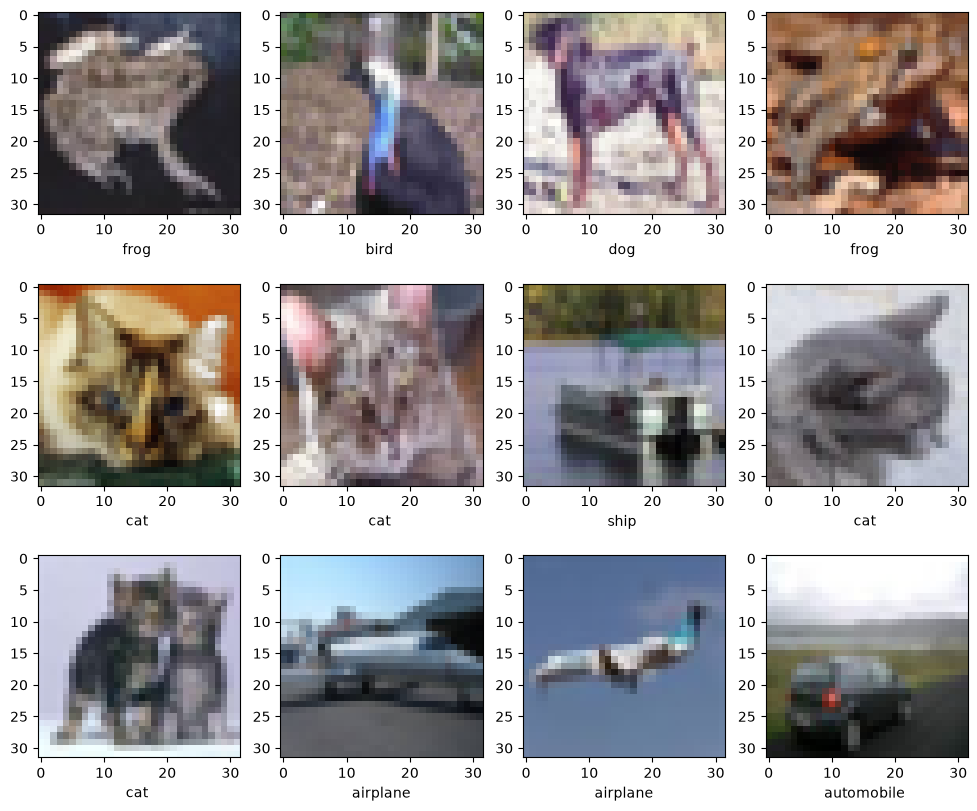

In [5]:
import matplotlib.pyplot as plt

%matplotlib inline



plt.figure(figsize=[12,10])

for i in range(12):

    plt.subplot(3, 4, i + 1)

    plt.xlabel(class_names[y_train[i, 0]])

    plt.imshow(X_train[i])

## Подготовка данных



Сейчас каждый пиксель изображения закодирован тройкой чисел (RGB) __от 0 до 255__. Однако лучше себя показывает подход, где значения входов нейросети распределены недалеко от 0.



Давайте приведём все данные в диапазон __`[0, 1]`__ — просто разделим на соответствующий коэффициент:

In [6]:
X_train = X_train / 255

X_val = X_val / 255

X_test = X_test / 255

Исполните код ниже для проверки, что все выполнено корректно.

In [7]:
assert np.shape(X_train) == (40000, 32, 32, 3), "data shape should not change"

assert 0.9 <= max(map(np.max, (X_train, X_val, X_test))) <= 1.05

assert 0.0 <= min(map(np.min, (X_train, X_val, X_test))) <= 0.1

assert len(np.unique(X_test / 255.)) > 10, "make sure you casted data to float type"

## Архитектура сети



Для начала реализуйте простую нейросеть:

1. принимает на вход картинки размера 32 x 32 x 3;

2. вытягивает их в вектор (`keras.layers.Flatten`);

3. пропускает через 1 или 2 полносвязных слоя;

4. выходной слой отдает вероятности принадлежности к каждому из 10 классов.

Создайте полносвязную сеть:

In [8]:
import keras

from keras import layers as L

from keras import backend as K

In [9]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=X_train.shape[1:]),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax'),
])

model.summary()

c:\Users\wolftik\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        98,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,722 (389.54 KB)

 Trainable params: 99,722 (389.54 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
dummy_pred = model.predict(X_train[:20])

assert dummy_pred.shape == (20, 10)

assert np.allclose(dummy_pred.sum(-1), 1)

print("Успех!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
Успех!


## Обучение сети



**Задание 1.1 (обязательно)** Будем минимизировать многоклассовую кроссэкнропию с помощью __sgd__. Вам нужно получить сеть, которая достигнет __не менее 45%__ __accuracy__ на тестовых данных.



__Важно:__ поскольку в y_train лежат номера классов, Керасу нужно либо указать sparse функции потерь и метрики оценки качества классификации (`sparse_categorical_crossentropy` и `sparse_categorical_accuracy`), либо конвертировать метки в one-hot формат.



### Полезные советы

* `model.compile` позволяет указать, какие метрики вы хотите вычислять.

* В `model.fit` можно передать валидационную выборку (`validation_data=[X_val, y_val]`), для отслеживания прогресса на ней. Также рекомендуем сохранять результаты в [tensorboard](https://keras.io/callbacks/#tensorboard) или [wandb](https://docs.wandb.ai/integrations/jupyter). **Важно: логи tensorboard не получится без боли посмотреть через colab.** Workaround: скачать логи и запустить tensorboard локально или помучаться [с этим](https://stackoverflow.com/questions/47818822/can-i-use-tensorboard-with-google-colab).

* По умолчанию сеть учится 1 эпоху. Совсем не факт, что вам этого хватит. Число эпох можно настроить в методе `fit` (`epochs`).

* Ещё у Кераса есть много [полезных callback-ов](https://keras.io/callbacks/), которые можно попробовать. Например, автоматическая остановка или подбор скорости обучения.

In [11]:
y_train, y_val = (keras.utils.to_categorical(y) for y in (y_train, y_val))

In [12]:
from pathlib import Path
import importlib.util

# Путь к ноутбуку содержит кириллицу ("Темы/..."), а чекпойнты и TensorBoard
# на Windows с таким путём падают, поэтому сохраняем в ~/.keras.
RUNS_DIR = Path.home() / '.keras' / 'cifar10_runs'
RUNS_DIR.mkdir(parents=True, exist_ok=True)

TB_AVAILABLE = importlib.util.find_spec('tensorboard') is not None
print('RUNS_DIR =', RUNS_DIR)
print('tensorboard установлен:', TB_AVAILABLE)


def make_callbacks(name, monitor='val_loss'):
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(RUNS_DIR / f'{name}.{{epoch:02d}}-{{val_loss:.2f}}.h5'),
            monitor=monitor, save_best_only=True),
        tf.keras.callbacks.EarlyStopping(
            monitor=monitor, patience=3, restore_best_weights=True),
    ]
    if TB_AVAILABLE:
        callbacks.append(tf.keras.callbacks.TensorBoard(
            log_dir=str(RUNS_DIR / 'logs' / name)))
    return callbacks


callbacks = make_callbacks('dense')

RUNS_DIR = C:\Users\wolftik\.keras\cifar10_runs
tensorboard установлен: True


In [13]:
model.compile(optimizer='sgd',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Используем уже подготовленную X_val вместо validation_split,
# чтобы EarlyStopping/ModelCheckpoint смотрели на ту же валидацию.
model.fit(X_train, y_train, batch_size=16, epochs=32,
          callbacks=callbacks, validation_data=(X_val, y_val))


Epoch 1/32
2431/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 662us/step - accuracy: 0.2946 - loss: 1.9397

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 835us/step - accuracy: 0.2962 - loss: 1.9360 - val_accuracy: 0.3427 - val_loss: 1.8344
Epoch 2/32
2495/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 646us/step - accuracy: 0.3656 - loss: 1.7642

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 766us/step - accuracy: 0.3657 - loss: 1.7641 - val_accuracy: 0.3912 - val_loss: 1.7195
Epoch 3/32
2462/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 634us/step - accuracy: 0.3900 - loss: 1.7034

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 760us/step - accuracy: 0.3902 - loss: 1.7025 - val_accuracy: 0.4073 - val_loss: 1.6669
Epoch 4/32
2481/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 650us/step - accuracy: 0.4092 - loss: 1.6524

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 775us/step - accuracy: 0.4090 - loss: 1.6527 - val_accuracy: 0.4054 - val_loss: 1.6644
Epoch 5/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 784us/step - accuracy: 0.4252 - loss: 1.6158 - val_accuracy: 0.3884 - val_loss: 1.7282
Epoch 6/32
2438/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 661us/step - accuracy: 0.4340 - loss: 1.5872

...

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 748us/step - accuracy: 0.4385 - loss: 1.5664 - val_accuracy: 0.4339 - val_loss: 1.5816
Epoch 8/32
2496/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 625us/step - accuracy: 0.4458 - loss: 1.5484

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 745us/step - accuracy: 0.4457 - loss: 1.5484 - val_accuracy: 0.4381 - val_loss: 1.5800
Epoch 9/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 744us/step - accuracy: 0.4521 - loss: 1.5315 - val_accuracy: 0.4376 - val_loss: 1.5812
Epoch 10/32
2440/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 639us/step - accuracy: 0.4547 - loss: 1.5209

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 765us/step - accuracy: 0.4543 - loss: 1.5214 - val_accuracy: 0.4416 - val_loss: 1.5621
Epoch 11/32
2481/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 650us/step - accuracy: 0.4584 - loss: 1.5089

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 773us/step - accuracy: 0.4586 - loss: 1.5089 - val_accuracy: 0.4439 - val_loss: 1.5508
Epoch 12/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 753us/step - accuracy: 0.4654 - loss: 1.4975 - val_accuracy: 0.4388 - val_loss: 1.5729
Epoch 13/32
2476/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 630us/step - accuracy: 0.4687 - loss: 1.4901

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 754us/step - accuracy: 0.4687 - loss: 1.4901 - val_accuracy: 0.4514 - val_loss: 1.5402
Epoch 14/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 771us/step - accuracy: 0.4724 - loss: 1.4779 - val_accuracy: 0.4528 - val_loss: 1.5423
Epoch 15/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 773us/step - accuracy: 0.4742 - loss: 1.4710 - val_accuracy: 0.4307 - val_loss: 1.5983
Epoch 16/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 2s 784us/step - accuracy: 0.4758 - loss: 1.4634 - val_accuracy: 0.4484 - val_loss: 1.5487


А теперь можно проверить качество вашей сети, выполнив код ниже:

In [14]:
from sklearn.metrics import accuracy_score



predict_x=model.predict(X_test)

classes_x=np.argmax(predict_x,axis=1)



test_acc = accuracy_score(y_test, classes_x)

print("\n Test_acc =", test_acc)

assert test_acc > 0.45, "Not good enough. Back to the drawing board :)"

print(" Not bad!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 475us/step

 Test_acc = 0.4578
 Not bad!


### Вывод по заданию 1.1 (полносвязная сеть)

- Тестовая точность: **0.4578** — порог 45% пройден, но с минимальным запасом.
- На обучении точность упёрлась в **0.45–0.46** и дальше почти не росла (val 0.45).
- Причина: `Flatten` превращает картинку 32×32×3 в вектор из 3072 чисел, и сеть теряет пространственную структуру изображения.
- Вывод: для картинок полносвязная сеть — плохой выбор, нужны свёртки.

## Карманная сверточная сеть



**Задание 1.2 (обязательно)** Реализуйте небольшую свёрточную сеть. Совсем небольшую:

1. Входной слой

2. Свёртка 3x3 с 10 фильтрами

3. Нелинейность на ваш вкус

4. Max-pooling 2x2

5. Вытягиваем оставшееся в вектор (Flatten)

6. Полносвязный слой на 100 нейронов

7. Нелинейность на ваш вкус

8. Выходной полносвязный слой с softmax



Обучите её так же, как и предыдущую сеть. Если всё хорошо, у вас получится accuracy не меньше __50%__.

In [15]:
new_model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(10, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax'),
])

new_model.summary()

c:\Users\wolftik\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 10)     │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2250)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 100)            │       225,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,390 (884.34 KB)

 Trainable params: 226,390 (884.34 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
new_callbacks = make_callbacks('pocket_conv')


In [17]:
new_model.compile(optimizer='sgd',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

new_model.fit(X_train, y_train, batch_size=16, epochs=32,
              callbacks=new_callbacks, validation_data=(X_val, y_val))


Epoch 1/32
2493/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3296 - loss: 1.8836

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.3298 - loss: 1.8831 - val_accuracy: 0.4044 - val_loss: 1.6935
Epoch 2/32
2491/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4513 - loss: 1.5604

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.4516 - loss: 1.5599 - val_accuracy: 0.4766 - val_loss: 1.4663
Epoch 3/32
2487/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5125 - loss: 1.3809

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.5127 - loss: 1.3806 - val_accuracy: 0.5269 - val_loss: 1.3305
Epoch 4/32
2474/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5513 - loss: 1.2749

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.5514 - loss: 1.2749 - val_accuracy: 0.5550 - val_loss: 1.2637
Epoch 5/32
2495/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5791 - loss: 1.2019

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.5791 - loss: 1.2016 - val_accuracy: 0.5717 - val_loss: 1.2261
Epoch 6/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.6020 - loss: 1.1362 - val_accuracy: 0.5501 - val_loss: 1.2902
Epoch 7/32
2477/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6209 - loss: 1.0839

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.6212 - loss: 1.0835 - val_accuracy: 0.5838 - val_loss: 1.2022
Epoch 8/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.6370 - loss: 1.0322 - val_accuracy: 0.5817 - val_loss: 1.2130
Epoch 9/32
2459/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6542 - loss: 0.9856

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.6542 - loss: 0.9863 - val_accuracy: 0.5975 - val_loss: 1.1644
Epoch 10/32
2491/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6704 - loss: 0.9398

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.6704 - loss: 0.9395 - val_accuracy: 0.6101 - val_loss: 1.1400
Epoch 11/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.6869 - loss: 0.8998 - val_accuracy: 0.6050 - val_loss: 1.1544
Epoch 12/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.7016 - loss: 0.8605 - val_accuracy: 0.6077 - val_loss: 1.1751
Epoch 13/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7142 - loss: 0.8223 - val_accuracy: 0.6042 - val_loss: 1.1679


Давайте посмотрим, смогла ли карманная сверточная сеть побить заданный порог по качеству:

In [18]:
from sklearn.metrics import accuracy_score



predict_x = new_model.predict(X_test)

classes_x = np.argmax(predict_x,axis=1)



test_acc = accuracy_score(y_test, classes_x)

print("\n Test_acc =", test_acc)

assert test_acc > 0.50, "Not good enough. Back to the drawing board :)"

print(" Not bad!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 844us/step

 Test_acc = 0.6022
 Not bad!


### Вывод по заданию 1.2 (карманная свёрточная сеть)

- Тестовая точность: **0.6022** — порог 50% пройден с запасом (примерно +14 п.п. к полносвязной сети).
- На валидации точность выросла до **0.61** к 10-й эпохе, а на обучении дошла до **0.71**.
- Разрыв train/val показывает начало переобучения: сеть уже подстраивается под обучающую выборку.
- Вывод: даже маленькая свёрточная сеть (10 фильтров 3×3 + max-pooling) заметно лучше полносвязной, потому что учитывает пространственную структуру картинки.

## Учимся учить



А теперь научимся сравнивать кривые обучения моделей — зависимости значения accuracy от количества итераций.



Вам потребуется реализовать _экспериментальный стенд_ — вспомогательный код, в который вы сможете подать несколько архитектур и методов обучения, чтобы он их обучил и вывел графики кривых обучения. Это можно сделать с помощью `keras.callbacks` — `TensorBoard` или `History`.



Будьте морально готовы, что на обучение уйдёт _много времени_. Даже если вы ограничитесь 10 эпохами. Пока идёт обучение, вы можете переключиться на другие задания или заняться чем-нибудь приятным: поспать, например.

**Задание 1.3 (опционально)** Попробуйте использовать различные методы оптимизации (sgd, momentum, adam) с параметрами по умолчанию. Какой из методов работает лучше?

Для удобства напишем класс Evaluator, который принимает в себя дикты виды {имя_оптимайзера: инстанс}, {имя модели: инстанс} и обучает всевозможные комбинации моделей с оптимайзерами при помощи метода fit (попутно записывая логи отдельно для каждой модели). Также пригодится метод evaluate для отображения итоговых скоров.

Пользоваться классом не обязательно. По умолчанию класс использует tensorboard. Если вы выше использовали wandb -- советуем дописать callback.

In [19]:
class Evaluator(list):
    def __init__(self, models, optimizers='adam', loss=keras.losses.categorical_crossentropy,
                 metrics=[keras.metrics.categorical_accuracy]):
        '''
            models: dict {name: model}
            optimizers: dict {name: optimizer} или один оптимизатор
        '''
        if not isinstance(models, dict):
            models = {'single_model': models}
        if not isinstance(optimizers, dict):
            optimizers = {str(optimizers.__class__): optimizers}
        super().__init__([(model_name, keras.models.clone_model(model), optimizer_name, optimizer)
                          for model_name, model in models.items()
                          for optimizer_name, optimizer in optimizers.items()])
        for _, model, _, optimizer in self:
            model.compile(optimizer=optimizer, loss=loss, metrics=metrics)

    def _tb_callback(self, model_name, optimizer_name):
        # TensorBoard пишем только если он установлен.
        if not TB_AVAILABLE:
            return []
        return [keras.callbacks.TensorBoard(
            log_dir=str(RUNS_DIR / 'logs' / '{}_{}'.format(model_name, optimizer_name)))]

    def fit(self, X, y, validation_data=(), max_epochs=100, verbose=0, callbacks=[], batch_size=32):
        if not isinstance(callbacks, list):
            callbacks = [callbacks]
        for model_name, model, optimizer_name, optimizer in tqdm_notebook(self):
            model.fit(X, y, validation_data=validation_data or None, epochs=max_epochs, verbose=verbose,
                      batch_size=batch_size, callbacks=callbacks + self._tb_callback(model_name, optimizer_name))

    def fit_generator(self, X, y, validation_data=(), max_epochs=100, verbose=1, callbacks=[], batch_size=32):
        datagen = keras.preprocessing.image.ImageDataGenerator(
            rotation_range=20,
            width_shift_range=0.2,
            height_shift_range=0.2,
            horizontal_flip=True
        )
        if not isinstance(callbacks, list):
            callbacks = [callbacks]
        for model_name, model, optimizer_name, optimizer in tqdm_notebook(self):
            model.fit_generator(datagen.flow(X, y, batch_size=batch_size), epochs=max_epochs,
                validation_data=validation_data or None, verbose=verbose,
                callbacks=callbacks + self._tb_callback(model_name, optimizer_name))

    def evaluate(self, X, y, metric):
        for model_name, model, optimizer_name, _ in self:
            print('Final score of {}_{} is {}'.format(model_name, optimizer_name,
                  metric(y_test, model.predict(X_test).argmax(axis=1))))

In [20]:
!pwd

"pwd" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


Прокомментируйте полученные результаты.

**Задание 1.4 (опционально)** Добавьте нормализацию по батчу (`BatchNormalization`) между свёрткой и активацией. Попробуйте использовать несколько нормализаций — в свёрточных и полносвязных слоях.

Для удобства реализуем класс Models, который по сути будет являться списком моделей с двумя методами: add (добавить слой ко всем моделям) и add_create (создать новую модель на основе базовой с дополнительным слоем). Пользоваться им необязательно, но вдруг :)

In [21]:
from collections import OrderedDict



class Models(OrderedDict):

    def __init__(self, models):

        if not isinstance(models, dict):

            models = OrderedDict({'base_model': models})

        super().__init__(models)



    def add(self, layer):

        for name, model in self.items():

            model.add(layer)



    def add_create(self, name, layer):

        base_model = next(iter(self.items()))[1]

        new_model = keras.models.clone_model(base_model)

        new_model.add(layer)

        self.update({name: new_model})



    def add_update(self, name, layer):

        base_model = self[next(reversed(self))]

        new_model = keras.models.clone_model(base_model)

        new_model.add(layer)

        self.update({name: new_model})



# Example of usage

# models = Models(keras.Sequential())

# models.add(L.InputLayer(input_shape=(32, 32, 3)))

# models.add(L.Convolution2D(filters=10, kernel_size=(3, 3)))

# models.add(L.MaxPooling2D())

# models.add_create('conv_batchnorm', L.BatchNormalization())

# models.add(L.Activation('relu'))

# ...

Прокомментируйте полученные результаты.

**Задание 1.5 (опционально)** Посмотрите на batch_size (параметр model.fit) - при большем батче модель будет быстрее проходить эпохи, но с совсем огромным батчом вам потребуется больше эпох для сходимости (т.к. сеть делает меньше шагов за одну эпоху).

Найдите такое значение, при котором модель быстрее достигает точности 55%. **Hint**: используйте early stopping callback.

**Задание 1.6 (опционально)** Попробуйте найти такую комбинацию метода обучения и нормализации, при которой сеть имеет наилучшую кривую обучения. Поясните, что вы понимаете под "наилучшей" кривой обучения.

## Свёрточная нейросеть здорового человека



**Задание 1.7 (обязательно попытаться)** Наигравшись выше, обучим большую свёрточную сеть, которая даст на тестовой выборке __accuracy больше 80%__. В этом задании вам потребуется провести эксперименты, сравнив их между собой в конце. Возможно, может быть несколько проще, если писать выводы во время или сразу после каждого эксперимента, после чего сделать общие выводы.



Рекомендуем начать с лучшей модели предыдущего задания и постепенно её улучшать. Вы можете использовать всё, что угодно: любые активации, сколь угодно большие свёрточные слои и глубокие сети. Единственное ограничение: __нельзя использовать предобученные сети и дополнительные данные__.



### Полезные советы

* Для начала, неплохо бы научить что-нибудь побольше, чем 10 фильтров 3x3.

* __Главное правило: одно изменение на эксперимент__. Если у вас есть 2 идеи по улучшению сети, сначала попробуйте их независимо. Может оказаться, что одно из них дало __+10%__ точности а другое __-7%__. А вы так и будете думать, что сделали 2 полезных изменения которые в сумме дают __+3%__. Если какая-то идея не работает — даже если она вам нравится - опишите ее и выкидывайте из дальнейших экспериментов.

* __Be careful or you will dropout__. Дропаут (`L.Dropout`) может позволить вам обучить в несколько раз бОльшую сеть без переобучения, выжав несколько процентов качества. Это круто, но не стоит сразу ставить dropout 50%. Во-первых, слишком сильный дропаут только ухудшит сеть (underfitting). Во-вторых, даже если дропаут улучшает качество, он замедляет обучение. Рекомендуем начинать с небольшого дропаута, быстро провести основные эксперименты, а потом жахнуть в 2 раза больше нейронов и дропаута ~~на ночь~~.

* __Аугментация данных__. Если котика слегка повернуть и подрезать (простите), он всё равно останется котиком. А в керасе есть [удобный класс](https://keras.io/preprocessing/image/), который поставит подрезание котиков на поток. Ещё можно сделать этот трюк в тесте: вертим картинку 10 раз, предсказываем вероятности и усредняем. Только один совет: прежде, чем учить, посмотрите глазами на аугментированные картинки. Если вы сами не можете их различить, то и сеть не сможет.

* __Don't just stack more layers__. Есть более эффективные способы организовать слои, чем простой Sequential. Вот пара идей: [Inception family](https://hacktilldawn.com/2016/09/25/inception-modules-explained-and-implemented/), [ResNet family](https://towardsdatascience.com/an-overview-of-resnet-and-its-variants-5281e2f56035?gi=9018057983ca), [Densely-connected convolutions](https://arxiv.org/abs/1608.06993). Только не копируйте архитектуру подчистую — вам скорее всего хватит меньшего размера.

* __Долго != плохо__. Более глубокие архитектуры обычно требуют бОльше эпох до сходимости. Это значит, что в первые несколько эпох они могут быть хуже менее глубоких аналогов. Дайте им время, запаситесь чаем и обмажьтесь batch-norm-ом.

In [22]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator



datagen = ImageDataGenerator(

    rotation_range=15,

    width_shift_range=0.1,

    height_shift_range=0.1,

    horizontal_flip=True

)

datagen.fit(X_train)

In [23]:
val_datagen = ImageDataGenerator()

# В X_train 40000 картинок (10000 ушли в X_val), поэтому делим 90/10.
split = int(len(X_train) * 0.9)
dg_x_train, dg_x_val = X_train[:split], X_train[split:]
dg_y_train, dg_y_val = y_train[:split], y_train[split:]

print('train/val:', len(dg_x_train), len(dg_x_val))

train/val: 36000 4000


In [24]:
final_model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation='softmax'),
])

final_model.summary()

c:\Users\wolftik\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,274 (2.26 MB)

 Trainable params: 591,274 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
final_callbacks = make_callbacks('final')


In [26]:
tf.keras.utils.plot_model(final_model, 'final_model.png', show_shapes=True)

You must install pydot (`pip install pydot`) for `plot_model` to work.


In [27]:
final_model.compile(optimizer='adam',
                    loss='categorical_crossentropy',
                    metrics=['accuracy'])

final_model.fit(datagen.flow(dg_x_train, dg_y_train, batch_size=16), epochs=32, callbacks=final_callbacks, validation_data=val_datagen.flow(dg_x_val, dg_y_val))

Epoch 1/32
2240/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3555 - loss: 1.7399

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.3557 - loss: 1.7394 - val_accuracy: 0.4750 - val_loss: 1.4230
Epoch 2/32
2244/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4854 - loss: 1.4274

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.4857 - loss: 1.4267 - val_accuracy: 0.5167 - val_loss: 1.4105
Epoch 3/32
2248/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5337 - loss: 1.2981

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.5336 - loss: 1.2981 - val_accuracy: 0.5888 - val_loss: 1.1453
Epoch 4/32
2245/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5553 - loss: 1.2358

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.5553 - loss: 1.2355 - val_accuracy: 0.6168 - val_loss: 1.0698
Epoch 5/32
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.5809 - loss: 1.1798 - val_accuracy: 0.6077 - val_loss: 1.0928
Epoch 6/32
2242/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5939 - loss: 1.1435

...

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6119 - loss: 1.0915 - val_accuracy: 0.6647 - val_loss: 0.9639
Epoch 9/32
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6252 - loss: 1.0653 - val_accuracy: 0.6400 - val_loss: 1.0613
Epoch 10/32
2248/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6269 - loss: 1.0577

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6269 - loss: 1.0576 - val_accuracy: 0.6702 - val_loss: 0.9565
Epoch 11/32
2240/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6305 - loss: 1.0510

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6304 - loss: 1.0511 - val_accuracy: 0.6740 - val_loss: 0.9401
Epoch 12/32
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6404 - loss: 1.0299 - val_accuracy: 0.6655 - val_loss: 0.9477
Epoch 13/32
2242/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6402 - loss: 1.0197

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6400 - loss: 1.0202 - val_accuracy: 0.6740 - val_loss: 0.9291
Epoch 14/32
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6439 - loss: 1.0105 - val_accuracy: 0.6777 - val_loss: 0.9669
Epoch 15/32
2244/2250 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6510 - loss: 0.9987

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6511 - loss: 0.9984 - val_accuracy: 0.7165 - val_loss: 0.7957
Epoch 16/32
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6543 - loss: 0.9910 - val_accuracy: 0.6775 - val_loss: 0.9439
Epoch 17/32
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6594 - loss: 0.9738 - val_accuracy: 0.7032 - val_loss: 0.8596
Epoch 18/32
2250/2250 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.6591 - loss: 0.9708 - val_accuracy: 0.6283 - val_loss: 1.1308


Момент истины: проверьте, какого качества достигла ваша сеть.

In [28]:
from sklearn.metrics import accuracy_score



predict_x=final_model.predict(X_test)

classes_x=np.argmax(predict_x,axis=1)



test_acc = accuracy_score(y_test, classes_x)

print("\n Test_acc =", test_acc)

if test_acc > 0.8:

    print("Это победа!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

 Test_acc = 0.7297


А теперь, опишите свои <s>ощущения</s> результаты от проведенных экспериментов.

### Вывод по заданию 1.7 (большая свёрточная сеть)

- Тестовая точность: **0.7297**. До цели 80% дотянуть не удалось.
- Лучшая валидационная точность — **0.7165** (15-я эпоха), затем `EarlyStopping` остановил обучение и вернул лучшие веса.
- Что помогло по сравнению с карманной сетью: больше фильтров (32 и 64), аугментация данных (`rotation_range`, сдвиги, `horizontal_flip`) и `Dropout`, которые уменьшили переобучение.
- Почему не 80%: учил на CPU, хватило ~18 эпох из 32, модель не успела как следует сойтись (точность на обучении ~0.65).
- Что попробовать дальше: больше эпох и фильтров, `BatchNormalization`, более глубокая архитектура (блоки свёрток подряд), планировщик learning rate.

## Итоговый вывод

- Прошёл путь от простого к сложному: полносвязная сеть (**0.46**), маленькая свёрточная (**0.60**), большая свёрточная (**0.73**). Каждый шаг заметно улучшал качество.
- Главное, что понял по теме:
  - свёртки сохраняют пространственную структуру изображения и работают на картинках намного лучше полносвязных слоёв;
  - `MaxPooling` уменьшает размер карты признаков и помогает выделять главное;
  - `Dropout` и аугментация данных борются с переобучением, а не «добавляют» точность сами по себе;
  - колбэки `EarlyStopping` и `ModelCheckpoint` экономят время и сохраняют лучшую модель.
- В **1.7** цель 80% не достигнута (получилось 0.7297), но есть рабочий результат и понятно, как его улучшать дальше.